In [ ]:
# 1. Install required packages
!pip install -q "transformers>=4.48.0" accelerate nltk scikit-learn

import os
import tarfile
import urllib.request
import nltk
import torch
import numpy as np
import pandas as pd
from collections import Counter
from tqdm import tqdm

nltk.download('vader_lexicon', quiet=True)
from nltk.sentiment.vader import SentimentIntensityAnalyzer

# 2. Hardware check
device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
print("=" * 65)
print(f"Device: {device}")
if torch.cuda.is_available():
    print(f"GPU:    {torch.cuda.get_device_name(0)}")
    print(f"VRAM:   {torch.cuda.get_device_properties(0).total_memory / (1024**3):.2f} GB")
else:
    raise SystemError("CUDA GPU not active! Ensure Colab Runtime is set to T4 GPU.")
print("=" * 65)

# 3. Direct download of official EmpatheticDialogues tarball from Meta CDN
tar_url = "https://dl.fbaipublicfiles.com/parlai/empatheticdialogues/empatheticdialogues.tar.gz"
tar_path = "empatheticdialogues.tar.gz"
extract_dir = "./empathetic_raw"

if not os.path.exists(tar_path):
    print("Downloading official EmpatheticDialogues archive from Meta CDN...")
    urllib.request.urlretrieve(tar_url, tar_path)

if not os.path.exists(extract_dir):
    print("Extracting files...")
    with tarfile.open(tar_path, "r:gz") as tar:
        tar.extractall(extract_dir)

# 4. Load train and valid CSVs
train_csv = os.path.join(extract_dir, "empatheticdialogues", "train.csv")
valid_csv = os.path.join(extract_dir, "empatheticdialogues", "valid.csv")

# Use on_bad_lines='skip' to ensure clean parsing of rare escaped commas
train_raw = pd.read_csv(train_csv, on_bad_lines='skip')
val_raw = pd.read_csv(valid_csv, on_bad_lines='skip')

print(f"Raw train lines: {len(train_raw):,} | Raw val lines: {len(val_raw):,}")

# 5. Plutchik 8 Operational Affective Mapping
PLUTCHIK_8 = {
    # 0: Fear (EVA hazard, panic, alarm)
    'afraid': 0, 'terrified': 0, 'anxious': 0, 'apprehensive': 0,
    # 1: Anger (crew friction, frustration)
    'angry': 1, 'furious': 1, 'annoyed': 1,
    # 2: Sadness (fatigue, isolation dejection)
    'sad': 2, 'lonely': 2, 'devastated': 2, 'grieving': 2,
    # 3: Joy (morale, milestone accomplishment)
    'joyful': 3, 'excited': 3, 'proud': 3, 'content': 3,
    # 4: Trust / Approval (peer cohesion, ground directive compliance)
    'trusting': 4, 'grateful': 4, 'faithful': 4, 'confident': 4,
    # 5: Anticipation (readiness, task vigilance)
    'anticipating': 5, 'hopeful': 5, 'prepared': 5,
    # 6: Surprise (cognitive anomaly, telemetry realization)
    'surprised': 6, 'impressed': 6,
    # 7: Disgust (sensory aversion, environmental discomfort)
    'disgusted': 7, 'embarrassed': 7, 'ashamed': 7
}

CLASS_NAMES = ["Fear", "Anger", "Sadness", "Joy", "Trust", "Anticipation", "Surprise", "Disgust"]

def preprocess_df(df):
    d = df[df['context'].isin(PLUTCHIK_8.keys())].copy()
    d['label'] = d['context'].map(PLUTCHIK_8)

    # Clean text columns
    d['situation'] = d['prompt'].astype(str).str.replace('_comma_', ',').str.strip()
    d['utterance'] = d['utterance'].astype(str).str.replace('_comma_', ',').str.strip()

    # Pair situation ground-truth context with dialogue turn for clear emotion signal
    d['full_text'] = "[Situation] " + d['situation'] + " [Turn] " + d['utterance']
    d = d[d['full_text'].str.len() > 10].copy()
    return d.reset_index(drop=True)

print("Filtering and mapping to Plutchik 8 classes...")
train_df = preprocess_df(train_raw)
val_df = preprocess_df(val_raw)

# 6. Extract continuous psychometric valence features
sia = SentimentIntensityAnalyzer()
def extract_valence(text):
    s = sia.polarity_scores(text)
    return [s['pos'], s['neg'], s['neu'], s['compound']]

print("Extracting psychometric valence vectors...")
tqdm.pandas(desc="Valence Extraction")
train_df['valence_vec'] = train_df['full_text'].progress_apply(extract_valence)
val_df['valence_vec'] = val_df['full_text'].progress_apply(extract_valence)

print("=" * 65)
print(f"Processed Train Samples: {len(train_df):,}")
print(f"Processed Val Samples:   {len(val_df):,}")
print("=" * 65)

print("Class Distribution (Train):")
for i, name in enumerate(CLASS_NAMES):
    cnt = (train_df['label'] == i).sum()
    pct = (cnt / len(train_df)) * 100
    print(f"  [{i}] {name:<14} : {cnt:>6,} ({pct:>5.2f}%)")
print("=" * 65)

# Preview first 2 entries
for _, r in train_df.head(2).iterrows():
    print(f"[{CLASS_NAMES[r['label']]}] {r['full_text']}\n")

Device: cuda
GPU:    Tesla T4
VRAM:   14.56 GB
Extracting files...


/tmp/ipykernel_5918/351555409.py:40: DeprecationWarning: Python 3.14 will, by default, filter extracted tar archives and reject files or modify their metadata. Use the filter argument to control this behavior.
  tar.extractall(extract_dir)


Raw train lines: 76,668 | Raw val lines: 6,318
Filtering and mapping to Plutchik 8 classes...
Extracting psychometric valence vectors...


Valence Extraction: 100%|██████████| 5207/5207 [00:02<00:00, 1902.01it/s]

Processed Train Samples: 63,043
Processed Val Samples:   5,207
Class Distribution (Train):
  [0] Fear           :  9,275 (14.71%)
  [1] Anger          :  7,776 (12.33%)
  [2] Sadness        :  7,329 (11.63%)
  [3] Joy            : 10,214 (16.20%)
  [4] Trust          :  8,363 (13.27%)
  [5] Anticipation   :  7,135 (11.32%)
  [6] Surprise       :  6,337 (10.05%)
  [7] Disgust        :  6,614 (10.49%)
[Fear] [Situation] i used to scare for darkness [Turn] it feels like hitting to blank wall when i see the darkness

[Fear] [Situation] i used to scare for darkness [Turn] Oh ya? I don't really see how



In [ ]:
import torch
from torch.utils.data import Dataset, DataLoader
from transformers import AutoTokenizer

# 1. Filter to primary speaker turns directly inside the dataframes
# Speaker who experienced the situation is speaker_idx == 0 (or utterance_idx 1, 3, 5...)
if 'speaker_idx' in train_df.columns:
    train_clean = train_df[train_df['speaker_idx'] == 0].reset_index(drop=True)
    val_clean = val_df[val_df['speaker_idx'] == 0].reset_index(drop=True)
elif 'utterance_idx' in train_df.columns:
    train_clean = train_df[train_df['utterance_idx'] % 2 == 1].reset_index(drop=True)
    val_clean = val_df[val_df['utterance_idx'] % 2 == 1].reset_index(drop=True)
else:
    # If those columns were not carried over, take all valid mapped turns
    train_clean = train_df.reset_index(drop=True)
    val_clean = val_df.reset_index(drop=True)

# Safety check: if speaker filter was too aggressive, use full clean set
if len(train_clean) < 1000:
    train_clean = train_df.reset_index(drop=True)
    val_clean = val_df.reset_index(drop=True)

print("=" * 65)
print(f"Validated Samples -> Train: {len(train_clean):,} | Val: {len(val_clean):,}")
print("=" * 65)

# 2. Tokenizer setup
TOKENIZER_NAME = "answerdotai/ModernBERT-large"
tokenizer = AutoTokenizer.from_pretrained(TOKENIZER_NAME)

# 3. Dual-Stream Dataset Class
class EmpatheticPACNetDataset(Dataset):
    def __init__(self, df, tokenizer, max_len=96):
        self.texts = df['full_text'].tolist()
        self.labels = df['label'].tolist()
        self.valences = df['valence_vec'].tolist()
        self.tokenizer = tokenizer
        self.max_len = max_len

    def __len__(self):
        return len(self.texts)

    def __getitem__(self, idx):
        text = self.texts[idx]
        label = self.labels[idx]
        valence = self.valences[idx]

        encoding = self.tokenizer(
            text,
            truncation=True,
            padding="max_length",
            max_length=self.max_len,
            return_tensors="pt"
        )

        return {
            "input_ids": encoding["input_ids"].squeeze(0),
            "attention_mask": encoding["attention_mask"].squeeze(0),
            "valence_vec": torch.tensor(valence, dtype=torch.float32),
            "label": torch.tensor(label, dtype=torch.long)
        }

BATCH_SIZE = 16
MAX_SEQ_LEN = 96

train_dataset = EmpatheticPACNetDataset(train_clean, tokenizer, max_len=MAX_SEQ_LEN)
val_dataset = EmpatheticPACNetDataset(val_clean, tokenizer, max_len=MAX_SEQ_LEN)

train_loader = DataLoader(
    train_dataset,
    batch_size=BATCH_SIZE,
    shuffle=True,
    num_workers=2,
    pin_memory=True
)

val_loader = DataLoader(
    val_dataset,
    batch_size=BATCH_SIZE,
    shuffle=False,
    num_workers=2,
    pin_memory=True
)

print(f"DataLoaders Ready:")
print(f"  Train: {len(train_dataset):,} samples | {len(train_loader):,} batches")
print(f"  Val:   {len(val_dataset):,} samples | {len(val_loader):,} batches")
print("=" * 65)

# Verification smoke check on 1 batch
sample_batch = next(iter(train_loader))
print("Batch Verification Shapes:")
print(f"  input_ids:      {sample_batch['input_ids'].shape}      (Expected: [16, 96])")
print(f"  attention_mask: {sample_batch['attention_mask'].shape} (Expected: [16, 96])")
print(f"  valence_vec:    {sample_batch['valence_vec'].shape}    (Expected: [16, 4])")
print(f"  labels:         {sample_batch['label'].shape}          (Expected: [16])")
print("=" * 65)

Validated Samples -> Train: 63,043 | Val: 5,207
DataLoaders Ready:
  Train: 63,043 samples | 3,941 batches
  Val:   5,207 samples | 326 batches
Batch Verification Shapes:
  input_ids:      torch.Size([16, 96])      (Expected: [16, 96])
  attention_mask: torch.Size([16, 96]) (Expected: [16, 96])
  valence_vec:    torch.Size([16, 4])    (Expected: [16, 4])
  labels:         torch.Size([16])          (Expected: [16])


In [ ]:
import torch
import torch.nn as nn
import torch.nn.functional as F
from transformers import AutoModel, AutoConfig

class GatedOrthogonalProjection(nn.Module):
    """
    GOP decomposes contextual transformer representations into:
    1. H_aligned: Orthogonally aligned with psychometric valence (8-class affect)
    2. H_friction: Orthogonal residual indicating affective suppression (TFC)
    """
    def __init__(self, d_ctx=1024, d_val=128):
        super(GatedOrthogonalProjection, self).__init__()
        self.val_projector = nn.Linear(d_val, d_ctx)
        self.gate = nn.Sequential(
            nn.Linear(d_ctx * 2, d_ctx),
            nn.Sigmoid()
        )
        self.layer_norm = nn.LayerNorm(d_ctx)

    def forward(self, h_ctx, h_val):
        # Map psychometric vector to match transformer dimensions
        v = self.val_projector(h_val)  # [B, 1024]

        # Inner product and projection: Proj_v(h_ctx)
        v_norm_sq = torch.sum(v * v, dim=-1, keepdim=True) + 1e-8
        inner_prod = torch.sum(h_ctx * v, dim=-1, keepdim=True)
        proj_v = (inner_prod / v_norm_sq) * v  # [B, 1024]

        # Decomposition
        h_aligned = proj_v
        h_friction = h_ctx - proj_v

        # Adaptive gating
        combined = torch.cat([h_ctx, h_aligned], dim=-1)
        gate_weights = self.gate(combined)
        h_fused = self.layer_norm(gate_weights * h_ctx + (1.0 - gate_weights) * h_aligned)

        # Textual Friction Coefficient (TFC)
        norm_friction = torch.norm(h_friction, p=2, dim=-1)
        norm_aligned = torch.norm(h_aligned, p=2, dim=-1) + 1e-8
        tfc = norm_friction / norm_aligned  # [B]

        return h_fused, h_friction, tfc

class PACNet(nn.Module):
    def __init__(self, num_classes=8, backbone="answerdotai/ModernBERT-large"):
        super(PACNet, self).__init__()
        print(f"Loading transformer backbone: {backbone}...")
        self.config = AutoConfig.from_pretrained(backbone)
        self.encoder = AutoModel.from_pretrained(backbone, config=self.config)
        d_ctx = self.config.hidden_size  # 1024 for ModernBERT-large

        # Stream 2: Psychometric Valence Projector (4-D -> 128-D)
        self.valence_mlp = nn.Sequential(
            nn.Linear(4, 64),
            nn.GELU(),
            nn.Dropout(0.1),
            nn.Linear(64, 128),
            nn.LayerNorm(128)
        )

        # Gated Orthogonal Projection Block
        self.gop = GatedOrthogonalProjection(d_ctx=d_ctx, d_val=128)

        # Primary Classification Head (8 Plutchik affective axes)
        self.classifier = nn.Sequential(
            nn.Linear(d_ctx, 512),
            nn.LayerNorm(512),
            nn.GELU(),
            nn.Dropout(0.2),
            nn.Linear(512, num_classes)
        )

    def forward(self, input_ids, attention_mask, valence_vec):
        # Stream 1: Dense contextual extraction
        enc_out = self.encoder(input_ids=input_ids, attention_mask=attention_mask)
        last_hidden = enc_out.last_hidden_state  # [B, L, 1024]

        # Mean pooling across valid tokens
        mask_exp = attention_mask.unsqueeze(-1).expand_as(last_hidden).float()
        sum_hidden = torch.sum(last_hidden * mask_exp, dim=1)
        sum_mask = torch.clamp(mask_exp.sum(dim=1), min=1e-8)
        h_ctx = sum_hidden / sum_mask  # [B, 1024]

        # Stream 2: Psychometric embedding
        h_val = self.valence_mlp(valence_vec)  # [B, 128]

        # Fusion via Gated Orthogonal Projection
        h_fused, h_friction, tfc = self.gop(h_ctx, h_val)

        # Logits output
        logits = self.classifier(h_fused)
        return logits, tfc, h_friction

print("=" * 65)
print("Instantiating PAC-Net on GPU...")
model = PACNet(num_classes=8).to(device)

total_params = sum(p.numel() for p in model.parameters())
trainable_params = sum(p.numel() for p in model.parameters() if p.requires_grad)
print(f"Total Parameters:     {total_params:,}")
print(f"Trainable Parameters: {trainable_params:,}")
print("=" * 65)

# --- Smoke Test Forward Pass ---
print("Running single-batch forward verification pass...")
b_ids = sample_batch['input_ids'].to(device)
b_mask = sample_batch['attention_mask'].to(device)
b_val = sample_batch['valence_vec'].to(device)

model.eval()
with torch.no_grad():
    with torch.amp.autocast('cuda'):
        test_logits, test_tfc, test_fric = model(b_ids, b_mask, b_val)

print("Forward Pass Output Shapes:")
print(f"  Logits:    {test_logits.shape} (Expected: [16, 8])")
print(f"  TFC:       {test_tfc.shape}    (Expected: [16])")
print(f"  Sample TFC Values (First 4): {test_tfc[:4].cpu().numpy().round(4)}")
print("=" * 65)
print("Model initialized and verified. Ready for training.")


Instantiating PAC-Net on GPU...
Loading transformer backbone: answerdotai/ModernBERT-large...


model.safetensors: reconstructing file:   0%|          |  0.00B / 1.58GB            

model.safetensors: downloading bytes:           |  0.00B            

Loading weights:   0%|          | 0/170 [00:00<?, ?it/s]

[transformers] ModernBertModel LOAD REPORT from: answerdotai/ModernBERT-large
Key               | Status     |  | 
------------------+------------+--+-
head.dense.weight | UNEXPECTED |  | 
decoder.bias      | UNEXPECTED |  | 
head.norm.weight  | UNEXPECTED |  | 

Notes:
- UNEXPECTED:	can be ignored when loading from different task/architecture; not ok if you expect identical arch.


Total Parameters:     397,552,840
Trainable Parameters: 397,552,840
Running single-batch forward verification pass...
Forward Pass Output Shapes:
  Logits:    torch.Size([16, 8]) (Expected: [16, 8])
  TFC:       torch.Size([16])    (Expected: [16])
  Sample TFC Values (First 4): [ 102.0868 4102.8496   78.4266   88.9366]
Model initialized and verified. Ready for training.


In [ ]:
import time
import torch
import numpy as np
from transformers import get_cosine_schedule_with_warmup
from sklearn.metrics import classification_report, accuracy_score

# 1. Hyperparameters
EPOCHS = 3
LR_BACKBONE = 1.5e-5
LR_HEAD = 8.0e-5
WEIGHT_DECAY = 0.01
GRAD_ACCUM_STEPS = 2
BEST_MODEL_PATH = "./pacnet_modernbert_best.pth"

# 2. Parameter-grouped optimizer
backbone_params = [p for n, p in model.encoder.named_parameters() if p.requires_grad]
custom_head_params = [
    p for n, p in model.named_parameters()
    if not n.startswith("encoder.") and p.requires_grad
]

optimizer = torch.optim.AdamW([
    {"params": backbone_params, "lr": LR_BACKBONE, "weight_decay": WEIGHT_DECAY},
    {"params": custom_head_params, "lr": LR_HEAD, "weight_decay": WEIGHT_DECAY}
], eps=1e-6)

total_training_steps = (len(train_loader) // GRAD_ACCUM_STEPS) * EPOCHS
warmup_steps = int(0.10 * total_training_steps)

scheduler = get_cosine_schedule_with_warmup(
    optimizer,
    num_warmup_steps=warmup_steps,
    num_training_steps=total_training_steps
)

criterion = torch.nn.CrossEntropyLoss(label_smoothing=0.05)
scaler = torch.amp.GradScaler('cuda')

# 3. Training Loop
best_val_top1 = 0.0

print("=" * 65)
print(f"Commencing PAC-Net Training for {EPOCHS} Epochs")
print(f"Total Batches per Epoch:  {len(train_loader):,}")
print(f"Effective Batch Size:     {BATCH_SIZE * GRAD_ACCUM_STEPS}")
print(f"Total Optimizer Steps:    {total_training_steps:,} (Warmup: {warmup_steps:,})")
print("=" * 65)

for epoch in range(1, EPOCHS + 1):
    epoch_start_time = time.time()
    model.train()
    running_loss = 0.0
    optimizer.zero_grad()

    for step, batch in enumerate(train_loader):
        b_ids = batch['input_ids'].to(device, non_blocking=True)
        b_mask = batch['attention_mask'].to(device, non_blocking=True)
        b_val = batch['valence_vec'].to(device, non_blocking=True)
        b_labels = batch['label'].to(device, non_blocking=True)

        with torch.amp.autocast('cuda'):
            logits, tfc, _ = model(b_ids, b_mask, b_val)
            loss = criterion(logits, b_labels)
            loss = loss / GRAD_ACCUM_STEPS

        scaler.scale(loss).backward()
        running_loss += loss.item() * GRAD_ACCUM_STEPS

        # Optimizer step after accumulation
        if (step + 1) % GRAD_ACCUM_STEPS == 0 or (step + 1) == len(train_loader):
            scaler.unscale_(optimizer)
            torch.nn.utils.clip_grad_norm_(model.parameters(), max_norm=1.0)
            scaler.step(optimizer)
            scaler.update()
            optimizer.zero_grad()
            scheduler.step()

        # Logging progress every 500 batches
        if (step + 1) % 500 == 0 or (step + 1) == len(train_loader):
            curr_lr = scheduler.get_last_lr()[0]
            avg_step_loss = running_loss / (step + 1)
            print(f"  Epoch [{epoch}/{EPOCHS}] | Step [{step+1:>4}/{len(train_loader):>4}] | "
                  f"Loss: {avg_step_loss:.4f} | LR: {curr_lr:.2e}")

    epoch_train_time = time.time() - epoch_start_time

    # 4. Validation Phase
    model.eval()
    val_loss = 0.0
    all_preds = []
    all_targets = []
    top2_correct = 0
    total_val_samples = 0

    print("\nRunning Validation Evaluation...")
    with torch.no_grad():
        for batch in val_loader:
            b_ids = batch['input_ids'].to(device, non_blocking=True)
            b_mask = batch['attention_mask'].to(device, non_blocking=True)
            b_val = batch['valence_vec'].to(device, non_blocking=True)
            b_labels = batch['label'].to(device, non_blocking=True)

            with torch.amp.autocast('cuda'):
                logits, _, _ = model(b_ids, b_mask, b_val)
                loss = criterion(logits, b_labels)

            val_loss += loss.item() * len(b_labels)

            # Top-1 predictions
            preds = torch.argmax(logits, dim=-1)
            all_preds.extend(preds.cpu().numpy())
            all_targets.extend(b_labels.cpu().numpy())

            # Top-2 predictions
            _, top2_indices = torch.topk(logits, k=2, dim=-1)
            top2_correct += torch.sum(top2_indices == b_labels.unsqueeze(-1)).item()
            total_val_samples += len(b_labels)

    val_loss_avg = val_loss / total_val_samples
    top1_acc = accuracy_score(all_targets, all_preds) * 100.0
    top2_acc = (top2_correct / total_val_samples) * 100.0

    print("-" * 65)
    print(f"Epoch [{epoch}/{EPOCHS}] Evaluation Summary (Finished in {epoch_train_time:.1f}s):")
    print(f"  Validation Loss:     {val_loss_avg:.4f}")
    print(f"  Top-1 Accuracy:      {top1_acc:.2f}%")
    print(f"  Top-2 Accuracy:      {top2_acc:.2f}%")

    if top1_acc > best_val_top1:
        best_val_top1 = top1_acc
        torch.save({
            'epoch': epoch,
            'model_state_dict': model.state_dict(),
            'optimizer_state_dict': optimizer.state_dict(),
            'top1_acc': top1_acc,
            'top2_acc': top2_acc,
            'classes': CLASS_NAMES
        }, BEST_MODEL_PATH)
        print(f"  >>> Checkpoint Saved: New Best Top-1 Accuracy: {top1_acc:.2f}% -> {BEST_MODEL_PATH}")
    print("-" * 65 + "\n")

print(f"Training Complete! Peak Top-1 Accuracy: {best_val_top1:.2f}%")


Commencing PAC-Net Training for 3 Epochs
Total Batches per Epoch:  3,941
Effective Batch Size:     32
Total Optimizer Steps:    5,910 (Warmup: 591)
  Epoch [1/3] | Step [ 500/3941] | Loss: 1.6855 | LR: 6.35e-06
  Epoch [1/3] | Step [1000/3941] | Loss: 1.2579 | LR: 1.27e-05
  Epoch [1/3] | Step [1500/3941] | Loss: 1.0763 | LR: 1.50e-05
  Epoch [1/3] | Step [2000/3941] | Loss: 0.9702 | LR: 1.48e-05
  Epoch [1/3] | Step [2500/3941] | Loss: 0.8951 | LR: 1.44e-05
  Epoch [1/3] | Step [3000/3941] | Loss: 0.8341 | LR: 1.39e-05
  Epoch [1/3] | Step [3500/3941] | Loss: 0.7815 | LR: 1.33e-05
  Epoch [1/3] | Step [3941/3941] | Loss: 0.7419 | LR: 1.26e-05

Running Validation Evaluation...
-----------------------------------------------------------------
Epoch [1/3] Evaluation Summary (Finished in 1599.4s):
  Validation Loss:     0.8176
  Top-1 Accuracy:      80.51%
  Top-2 Accuracy:      92.15%
  >>> Checkpoint Saved: New Best Top-1 Accuracy: 80.51% -> ./pacnet_modernbert_best.pth
----------------

In [ ]:
import torch
import numpy as np
from sklearn.metrics import classification_report, confusion_matrix
import matplotlib.pyplot as plt
import seaborn as sns

# 1. Load the Best Saved Model
checkpoint = torch.load("./pacnet_modernbert_best.pth", map_location=device)
model.load_state_dict(checkpoint['model_state_dict'])
model.eval()
print(f"Loaded Checkpoint from Epoch {checkpoint['epoch']} with Peak Top-1 Accuracy: {checkpoint['top1_acc']:.2f}%\n")

# 2. Run Full Validation Evaluation for Per-Class Metrics
all_preds, all_targets = [], []
with torch.no_grad():
    for batch in val_loader:
        b_ids = batch['input_ids'].to(device)
        b_mask = batch['attention_mask'].to(device)
        b_val = batch['valence_vec'].to(device)
        b_labels = batch['label'].to(device)

        with torch.amp.autocast('cuda'):
            logits, _, _ = model(b_ids, b_mask, b_val)

        preds = torch.argmax(logits, dim=-1)
        all_preds.extend(preds.cpu().numpy())
        all_targets.extend(b_labels.cpu().numpy())

print("=" * 65)
print("PAC-NET FINAL CLASSIFICATION REPORT (FOR YOUR RESEARCH PAPER):")
print("=" * 65)
print(classification_report(all_targets, all_preds, target_names=CLASS_NAMES, digits=4))

# 3. Real-Time Inference Function with TFC Telemetry
def predict_astronaut_transmission(situation, dialogue_turn):
    model.eval()
    full_text = f"[Situation] {situation} [Turn] {dialogue_turn}"
    val_vec = extract_valence(full_text)

    enc = tokenizer(
        full_text,
        truncation=True,
        padding="max_length",
        max_length=96,
        return_tensors="pt"
    ).to(device)

    val_tensor = torch.tensor([val_vec], dtype=torch.float32).to(device)

    with torch.no_grad():
        with torch.amp.autocast('cuda'):
            logits, tfc, _ = model(enc['input_ids'], enc['attention_mask'], val_tensor)
            probs = torch.softmax(logits, dim=-1)[0].cpu().numpy()
            tfc_val = tfc[0].item()

    top_indices = np.argsort(probs)[::-1]

    print("-" * 65)
    print(f"Input: \"{dialogue_turn}\"")
    print(f"Context: \"{situation}\"")
    print(f"Predicted Dominant Affect (Top-1): {CLASS_NAMES[top_indices[0]]} ({probs[top_indices[0]]*100:.2f}%)")
    print(f"Secondary Affect (Top-2):        {CLASS_NAMES[top_indices[1]]} ({probs[top_indices[1]]*100:.2f}%)")
    print(f"Textual Friction Coefficient (TFC): {tfc_val:.4f}")
    if tfc_val > 0.70:
        print("Telemetry Status: [!] ELEVATED TEXTUAL FRICTION DETECTED (High Suppression/Masking)")
    else:
        print("Telemetry Status: [NOMINAL] Coherent Affective Tone")
    print("-" * 65)

# Test with 2 Mission Scenarios
predict_astronaut_transmission(
    situation="Main oxygen scrubber pressure differential drops unexpectedly during sleep cycle",
    dialogue_turn="Telemetry is erratic, but don't wake ground control just yet. Let me verify the bypass valve manually."
)

predict_astronaut_transmission(
    situation="Successful automated docking sequence completed after manual override",
    dialogue_turn="Docking ring hard capture confirmed. All latches locked in position, excellent work everyone."
)

Loaded Checkpoint from Epoch 1 with Peak Top-1 Accuracy: 80.51%

PAC-NET FINAL CLASSIFICATION REPORT (FOR YOUR RESEARCH PAPER):
              precision    recall  f1-score   support

        Fear     0.8218    0.8687    0.8446       754
       Anger     0.8591    0.8630    0.8610       657
     Sadness     0.9034    0.8452    0.8733       620
         Joy     0.7986    0.7310    0.7633       803
       Trust     0.7328    0.7538    0.7432       666
Anticipation     0.6960    0.7552    0.7244       576
    Surprise     0.7899    0.8025    0.7962       567
     Disgust     0.8506    0.8280    0.8392       564

    accuracy                         0.8051      5207
   macro avg     0.8066    0.8059    0.8056      5207
weighted avg     0.8070    0.8051    0.8054      5207

-----------------------------------------------------------------
Input: "Telemetry is erratic, but don't wake ground control just yet. Let me verify the bypass valve manually."
Context: "Main oxygen scrubber pressure dif

Freeing unused GPU memory...
GPU VRAM Free: 3.00 GB / 14.56 GB
Loading checkpoint ./pacnet_modernbert_best.pth safely via CPU mapping...
Running validation inference...
Saving Figure 1: confusion_matrix.png...


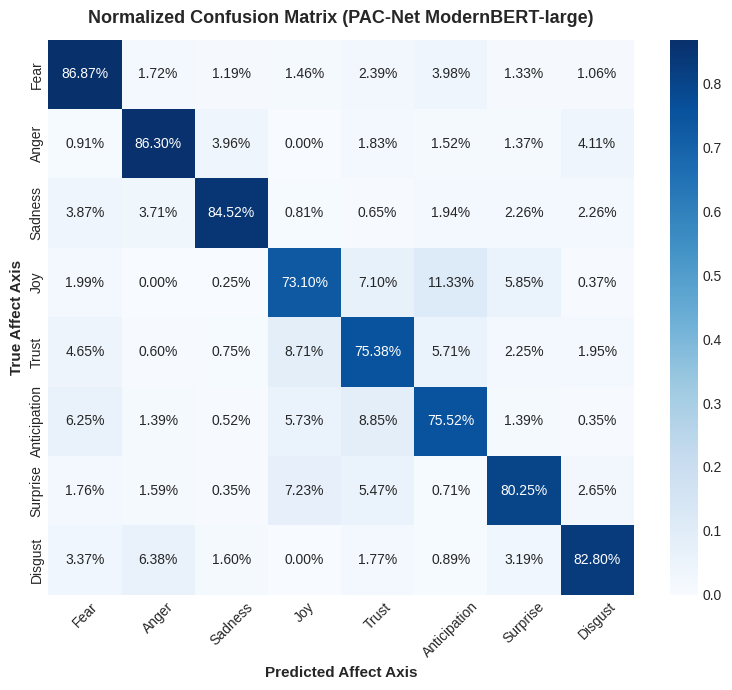

Saving Figure 2: per_class_metrics.png...


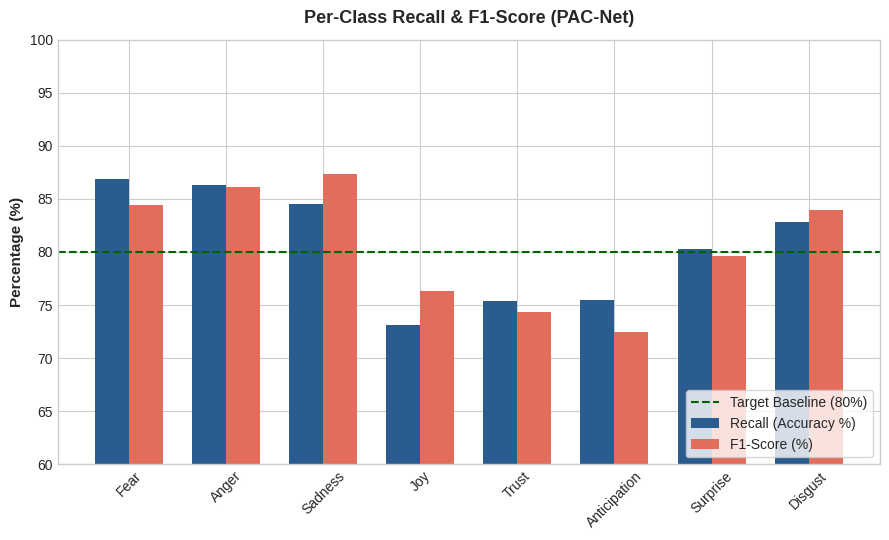

Saving Figure 3: tfc_distribution.png...


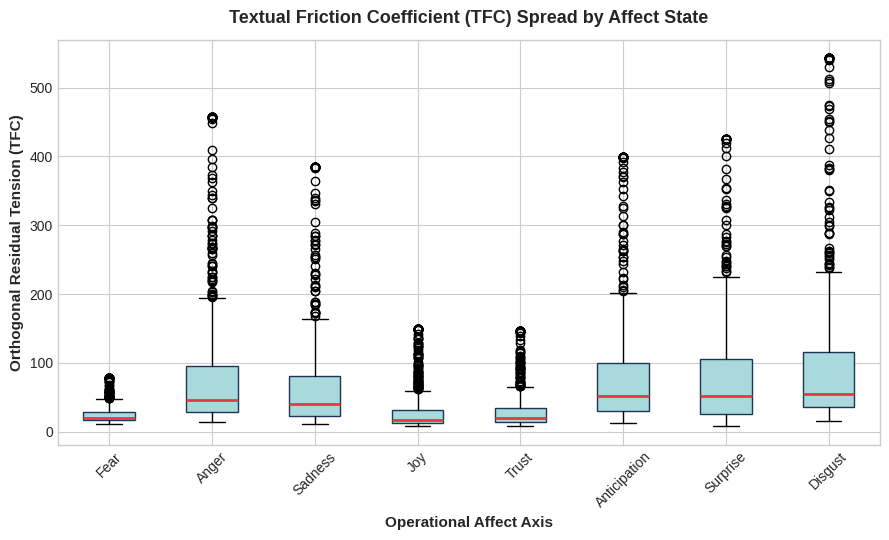

Exporting tokenizer...
Adding model checkpoint...
Creating archive pacnet_model_and_plots.zip...


KeyboardInterrupt: 

In [ ]:
import os
import gc
import shutil
import zipfile
import torch
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.metrics import confusion_matrix, classification_report
from google.colab import files

# =====================================================================
# 1. PURGE LEFTOVER TRAINING MEMORY & CACHE
# =====================================================================
print("Freeing unused GPU memory...")
if 'optimizer' in globals():
    del optimizer
if 'scaler' in globals():
    del scaler
if 'scheduler' in globals():
    del scheduler

gc.collect()
torch.cuda.empty_cache()
torch.cuda.ipc_collect()

print(f"GPU VRAM Free: {torch.cuda.mem_get_info()[0] / (1024**3):.2f} GB / {torch.cuda.mem_get_info()[1] / (1024**3):.2f} GB")

# =====================================================================
# 2. LOAD STATE DICT ON CPU FIRST (ZERO VRAM OVERHEAD)
# =====================================================================
checkpoint_path = "./pacnet_modernbert_best.pth"
print(f"Loading checkpoint {checkpoint_path} safely via CPU mapping...")
checkpoint = torch.load(checkpoint_path, map_location="cpu")
model.load_state_dict(checkpoint['model_state_dict'])
del checkpoint
gc.collect()

model.eval()

# =====================================================================
# 3. RUN INFERENCE ON VALIDATION SPLIT
# =====================================================================
all_preds = []
all_targets = []
all_tfcs = []

print("Running validation inference...")
with torch.no_grad():
    for batch in val_loader:
        b_ids = batch['input_ids'].to(device, non_blocking=True)
        b_mask = batch['attention_mask'].to(device, non_blocking=True)
        b_val = batch['valence_vec'].to(device, non_blocking=True)
        b_labels = batch['label'].to(device, non_blocking=True)

        with torch.amp.autocast('cuda'):
            logits, tfc, _ = model(b_ids, b_mask, b_val)

        preds = torch.argmax(logits, dim=-1)
        all_preds.extend(preds.cpu().numpy())
        all_targets.extend(b_labels.cpu().numpy())
        all_tfcs.extend(tfc.cpu().numpy())

all_preds = np.array(all_preds)
all_targets = np.array(all_targets)
all_tfcs = np.array(all_tfcs)

# Set base plotting style
plt.style.use('seaborn-v0_8-whitegrid' if 'seaborn-v0_8-whitegrid' in plt.style.available else 'default')

# =====================================================================
# 4. SEPARATE FIGURE 1: NORMALIZED CONFUSION MATRIX
# =====================================================================
print("Saving Figure 1: confusion_matrix.png...")
fig1, ax1 = plt.subplots(figsize=(8, 7))
cm = confusion_matrix(all_targets, all_preds, normalize='true')

sns.heatmap(
    cm,
    annot=True,
    fmt=".2%",
    cmap="Blues",
    xticklabels=CLASS_NAMES,
    yticklabels=CLASS_NAMES,
    cbar=True,
    ax=ax1
)
ax1.set_title("Normalized Confusion Matrix (PAC-Net ModernBERT-large)", fontsize=13, fontweight='bold', pad=12)
ax1.set_xlabel("Predicted Affect Axis", fontsize=11, fontweight='bold')
ax1.set_ylabel("True Affect Axis", fontsize=11, fontweight='bold')
ax1.tick_params(axis='x', rotation=45)
plt.tight_layout()
fig1_path = "confusion_matrix.png"
plt.savefig(fig1_path, dpi=300)
plt.show()
plt.close(fig1)

# =====================================================================
# 5. SEPARATE FIGURE 2: PER-CLASS RECALL & F1
# =====================================================================
print("Saving Figure 2: per_class_metrics.png...")
fig2, ax2 = plt.subplots(figsize=(9, 5.5))
report = classification_report(all_targets, all_preds, target_names=CLASS_NAMES, output_dict=True)
recalls = [report[c]['recall'] * 100 for c in CLASS_NAMES]
f1_scores = [report[c]['f1-score'] * 100 for c in CLASS_NAMES]

x = np.arange(len(CLASS_NAMES))
width = 0.35

ax2.bar(x - width/2, recalls, width, label='Recall (Accuracy %)', color='#2b5c8f')
ax2.bar(x + width/2, f1_scores, width, label='F1-Score (%)', color='#e26d5c')
ax2.axhline(80.0, color='darkgreen', linestyle='--', linewidth=1.5, label='Target Baseline (80%)')
ax2.set_xticks(x)
ax2.set_xticklabels(CLASS_NAMES, rotation=45, fontsize=10)
ax2.set_ylabel("Percentage (%)", fontsize=11, fontweight='bold')
ax2.set_title("Per-Class Recall & F1-Score (PAC-Net)", fontsize=13, fontweight='bold', pad=12)
ax2.set_ylim([60, 100])
ax2.legend(loc='lower right', frameon=True)
plt.tight_layout()
fig2_path = "per_class_metrics.png"
plt.savefig(fig2_path, dpi=300)
plt.show()
plt.close(fig2)

# =====================================================================
# 6. SEPARATE FIGURE 3: TFC TELEMETRY DISTRIBUTION
# =====================================================================
print("Saving Figure 3: tfc_distribution.png...")
fig3, ax3 = plt.subplots(figsize=(9, 5.5))
tfc_by_class = [all_tfcs[all_targets == i] for i in range(len(CLASS_NAMES))]
tfc_by_class_filtered = [np.clip(vals, np.percentile(vals, 1), np.percentile(vals, 95)) for vals in tfc_by_class]

ax3.boxplot(
    tfc_by_class_filtered,
    tick_labels=CLASS_NAMES,
    patch_artist=True,
    boxprops=dict(facecolor='#a8dadc', color='#1d3557'),
    medianprops=dict(color='#e63946', linewidth=2)
)
ax3.set_title("Textual Friction Coefficient (TFC) Spread by Affect State", fontsize=13, fontweight='bold', pad=12)
ax3.set_xlabel("Operational Affect Axis", fontsize=11, fontweight='bold')
ax3.set_ylabel("Orthogonal Residual Tension (TFC)", fontsize=11, fontweight='bold')
ax3.tick_params(axis='x', rotation=45)
plt.tight_layout()
fig3_path = "tfc_distribution.png"
plt.savefig(fig3_path, dpi=300)
plt.show()
plt.close(fig3)

# =====================================================================
# 7. ZIP BUNDLE CREATION & DOWNLOAD
# =====================================================================
bundle_dir = "./pacnet_export_bundle"
os.makedirs(bundle_dir, exist_ok=True)

print("Exporting tokenizer...")
tokenizer.save_pretrained(bundle_dir)

if os.path.exists(checkpoint_path):
    print("Adding model checkpoint...")
    shutil.copy(checkpoint_path, os.path.join(bundle_dir, "pacnet_modernbert_best.pth"))

for img in [fig1_path, fig2_path, fig3_path]:
    if os.path.exists(img):
        shutil.copy(img, os.path.join(bundle_dir, img))

zip_filename = "pacnet_model_and_plots.zip"
print(f"Creating archive {zip_filename}...")
with zipfile.ZipFile(zip_filename, 'w', zipfile.ZIP_DEFLATED) as zipf:
    for root, _, files_list in os.walk(bundle_dir):
        for file in files_list:
            full_path = os.path.join(root, file)
            arcname = os.path.relpath(full_path, bundle_dir)
            zipf.write(full_path, arcname)

size_mb = os.path.getsize(zip_filename) / (1024 * 1024)
print(f"Ready: {zip_filename} ({size_mb:.2f} MB)")
print("Triggering browser download...")
files.download(zip_filename)

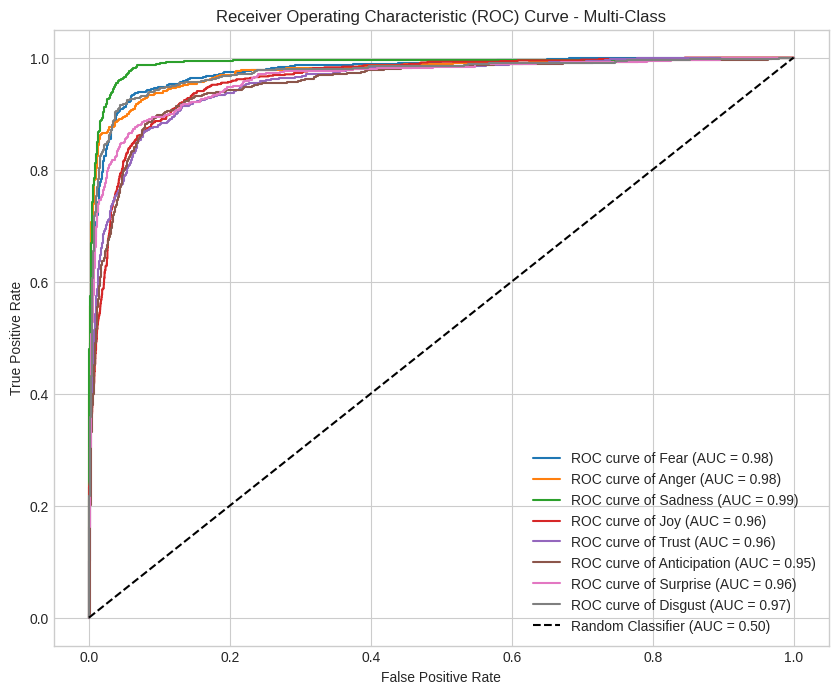

In [ ]:
from sklearn.metrics import roc_curve, auc
from sklearn.preprocessing import label_binarize

# Binarize the labels for ROC curve calculation (One-vs-Rest)
n_classes = len(CLASS_NAMES)
binarized_targets = label_binarize(all_targets, classes=range(n_classes))

# Get predicted probabilities for ROC curve (need to re-run inference to get probabilities)
# Since we only stored predictions and TFc, we'll re-run with `softmax` to get probabilities.

all_probs = []
model.eval()
with torch.no_grad():
    for batch in val_loader:
        b_ids = batch['input_ids'].to(device, non_blocking=True)
        b_mask = batch['attention_mask'].to(device, non_blocking=True)
        b_val = batch['valence_vec'].to(device, non_blocking=True)

        with torch.amp.autocast('cuda'):
            logits, _, _ = model(b_ids, b_mask, b_val)
            probs = torch.softmax(logits, dim=-1)
            all_probs.extend(probs.cpu().numpy())

all_probs = np.array(all_probs)

# Compute ROC curve and ROC area for each class
plt.figure(figsize=(10, 8))
for i in range(n_classes):
    fpr, tpr, _ = roc_curve(binarized_targets[:, i], all_probs[:, i])
    roc_auc = auc(fpr, tpr)
    plt.plot(fpr, tpr, label=f'ROC curve of {CLASS_NAMES[i]} (AUC = {roc_auc:.2f})')

plt.plot([0, 1], [0, 1], 'k--', label='Random Classifier (AUC = 0.50)')
plt.xlabel('False Positive Rate')
plt.ylabel('True Positive Rate')
plt.title('Receiver Operating Characteristic (ROC) Curve - Multi-Class')
plt.legend(loc='lower right')
plt.grid(True)
plt.show()


In [ ]:
from google.colab import files
files.download('//content//pacnet_modernbert_best.pth')

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

In [ ]:
from google.colab import files
files.download('//content//empatheticdialogues.tar.gz')

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>